# Same moments, different local densities: a zero-FID toy example

Let $P$ be a two-dimensional standard normal and $Q$ a mixture of three normals.
Their **population means and full covariance matrices agree exactly**, so the
Gaussian-moment FID is zero, although their local densities differ substantially.
Analytic 3D density surfaces and contour maps show the different shapes directly.
The scatterplots then compare the exact relative density ratio with one neural fit:
$$r_0(x)=\frac{2p(x)}{p(x)+q(x)}\in[0,2].$$

Open this notebook in VS Code, select a Python kernel with the
[simulation dependencies](requirements.txt), and **Run All**. Run from anywhere
inside the checkout, or set `RDR_REPO_ROOT` to the checkout path. This is one
CPU illustration with independent training, validation and evaluation samples.
The settings below control the example; no data download or repeated jobs are needed.
Set `OUTPUT_DIR` to export all three figures as PDF/PNG and the numerical summary as JSON.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

# Inline figures in VS Code/Jupyter, including kernels started with MPLBACKEND=Agg.
get_ipython().run_line_magic("matplotlib", "inline")

repo_hint = os.environ.get("RDR_REPO_ROOT")
search_roots = [Path(repo_hint).expanduser()] if repo_hint else [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p.resolve() for p in search_roots
                  if (p / "utils" / "networks.py").is_file()
                  and (p / "experiments" / "simulations").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Run inside the checkout or set RDR_REPO_ROOT to its path.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import scipy
from scipy.special import expit, logsumexp
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import torch

from utils.networks import make_ratio_mlp
from utils.training import fit_ratio_mlp

CONFIG = {
    "seed": 20261004,
    "component_sd": 0.40,  # 0 < s < 1; radius adjusts to keep Cov(Q) = I_2
    "n_train": 2000,       # observations from EACH distribution
    "n_validation": 1000,
    "n_evaluation": 5000,
    "n_scatter_per_distribution": 1500,
    "architecture": "bottleneck8_residual64",
    "output_alpha": 2.0,   # sigmoid slope; the P/Q midpoint weight stays 1/2
    "loss": "hellinger",
    "min_epochs": 300,
    "max_epochs": 1000,
    "patience": 30,
}
OUTPUT_DIR = None  # e.g. REPO_ROOT / "runs" / "moment_matched_fid_toy"
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})
print(json.dumps(CONFIG, indent=2))

GUI event loop hook disabled.
{
  "seed": 20261004,
  "component_sd": 0.4,
  "n_train": 2000,
  "n_validation": 1000,
  "n_evaluation": 5000,
  "n_scatter_per_distribution": 1500,
  "architecture": "bottleneck8_residual64",
  "output_alpha": 2.0,
  "loss": "hellinger",
  "min_epochs": 300,
  "max_epochs": 1000,
  "patience": 30
}


## Construction and exact moment calculation

Choose $s=0.4$, $a=\sqrt{2(1-s^2)}$, and
$$m_1=(a,0),\quad m_2=(-a/2,\sqrt{3}a/2),\quad
m_3=(-a/2,-\sqrt{3}a/2).$$
Then
$$P=N_2(0,I_2),\qquad Q=\frac13\sum_{k=1}^3 N_2(m_k,s^2 I_2).$$
The component means sum to zero, and their average outer product is
$(a^2/2)I_2$. Consequently,
$$\mu_Q=\mu_P=0,\qquad
\Sigma_Q=s^2I_2+\frac13\sum_{k=1}^3m_km_k^\top
=(s^2+a^2/2)I_2=I_2=\Sigma_P.$$
This matches the cross-covariance as well as both marginal variances.
Nevertheless, $E_Q[X_1^3]=a^3/4>0=E_P[X_1^3]$, so $P\ne Q$.

Using the [FID formula of Heusel et al., Eq. (6)](https://arxiv.org/pdf/1706.08500),
$$\operatorname{FID}_{\mathrm{id}}(P,Q)=\|\mu_P-\mu_Q\|^2+
\operatorname{tr}\!\left(\Sigma_P+\Sigma_Q-
2(\Sigma_P^{1/2}\Sigma_Q\Sigma_P^{1/2})^{1/2}\right)=0.$$
Here the two coordinates themselves are the features (the identity feature map).
This is the Gaussian-moment analogue of image FID; applying a nonlinear feature
map need not preserve these matched moments. The Wasserstein distance between
the actual nonidentical distributions is not zero.

The code checks the population identity using the mixture parameters.
Finite samples have sampling error, so their plug-in FID will generally be positive.
We keep the samples i.i.d.; we do not recenter or rescale them to force a sample FID of zero.

In [2]:
s = float(CONFIG["component_sd"])
if not 0 < s < 1:
    raise ValueError("component_sd must lie strictly between 0 and 1.")
a = np.sqrt(2 * (1 - s**2))
weights = np.full(3, 1 / 3)
means = a * np.array([[1.0, 0.0], [-0.5, np.sqrt(3) / 2],
                      [-0.5, -np.sqrt(3) / 2]])
component_cov = s**2 * np.eye(2)
mean_p, cov_p = np.zeros(2), np.eye(2)
mean_q = weights @ means
centered_means = means - mean_q
cov_q = component_cov + (centered_means.T * weights) @ centered_means
np.testing.assert_allclose(mean_q, mean_p, atol=1e-14, rtol=0)
np.testing.assert_allclose(cov_q, cov_p, atol=1e-14, rtol=0)


def psd_sqrt(matrix):
    """Real symmetric square root; tolerate only floating-point negative eigenvalues."""
    eigenvalues, eigenvectors = np.linalg.eigh((matrix + matrix.T) / 2)
    if eigenvalues.min() < -1e-12:
        raise ValueError("Covariance matrix is not positive semidefinite.")
    return (eigenvectors * np.sqrt(np.maximum(eigenvalues, 0))) @ eigenvectors.T


def gaussian_moment_fid(mu_p, sigma_p, mu_q, sigma_q):
    root_p = psd_sqrt(sigma_p)
    covariance_term = np.trace(sigma_p + sigma_q
                               - 2 * psd_sqrt(root_p @ sigma_q @ root_p))
    value = float(np.sum((mu_p - mu_q)**2) + covariance_term)
    if value < -1e-10:
        raise ArithmeticError("Unexpected negative Gaussian-moment FID.")
    return max(value, 0.0)  # remove roundoff only, not finite-sample discrepancy


population_fid_numeric = gaussian_moment_fid(mean_p, cov_p, mean_q, cov_q)
assert population_fid_numeric < 1e-12
print("P mean:", mean_p, "\nQ mean:", mean_q)
print("P covariance:\n", cov_p, "\nQ covariance:\n", cov_q)
print("Population FID (identity features): exactly 0 by the calculation above")
print(f"Numerical population check: {population_fid_numeric:.3e}")
print(f"Q component means:\n{means}")
print(f"Third moment E_Q[X_1^3] = {a**3 / 4:.6f}; E_P[X_1^3] = 0")

P mean: [0. 0.] 
Q mean: [-6.51193784e-18  2.26665383e-18]
P covariance:
 [[1. 0.]
 [0. 1.]] 
Q covariance:
 [[ 1.00000000e+00 -4.12899277e-19]
 [ 8.36569240e-18  1.00000000e+00]]
Population FID (identity features): exactly 0 by the calculation above
Numerical population check: 2.220e-16
Q component means:
[[ 1.29614814  0.        ]
 [-0.64807407  1.12249722]
 [-0.64807407 -1.12249722]]
Third moment E_Q[X_1^3] = 0.544382; E_P[X_1^3] = 0


## Sampling and analytic RDR

The six data streams (train/validation/evaluation $\times$ $P/Q$) are independent.
Initialization and plotting use separate stream keys. Evaluation observations
are used only for the final metrics and scatterplots. The exact ratio is computed
from log densities, avoiding division of tiny densities in the tails.

In [3]:
SPLIT_IDS = {"train": 0, "validation": 1, "evaluation": 2}


def sample_p(n, rng):
    return rng.normal(size=(n, 2))


def sample_q(n, rng):
    components = rng.choice(3, size=n, p=weights)
    return means[components] + s * rng.normal(size=(n, 2))


def log_p(x):
    x = np.asarray(x, dtype=float).reshape(-1, 2)
    return -np.log(2 * np.pi) - 0.5 * np.sum(x**2, axis=1)


def log_q(x):
    x = np.asarray(x, dtype=float).reshape(-1, 2)
    sq_distance = np.sum((x[:, None, :] - means[None, :, :])**2, axis=2)
    log_components = -np.log(2 * np.pi * s**2) - sq_distance / (2 * s**2)
    return logsumexp(np.log(weights) + log_components, axis=1)


def true_rdr(x):
    return 2 * expit(log_p(x) - log_q(x))


samples = {}
for split, split_id in SPLIT_IDS.items():
    n = CONFIG[f"n_{split}"]
    samples[split] = tuple(sampler(n, np.random.default_rng(
        np.random.SeedSequence([CONFIG["seed"], split_id, source_id])))
        for source_id, sampler in enumerate((sample_p, sample_q)))
    print(f"{split:>10}: {n:,} P + {n:,} Q observations")
x_p_eval, x_q_eval = samples["evaluation"]
truth_p, truth_q = true_rdr(x_p_eval), true_rdr(x_q_eval)
empirical_fid = gaussian_moment_fid(
    x_p_eval.mean(axis=0), np.cov(x_p_eval, rowvar=False),
    x_q_eval.mean(axis=0), np.cov(x_q_eval, rowvar=False))
print(f"Evaluation-sample plug-in FID: {empirical_fid:.6f} (sampling error)")
print(f"Exact RDR at origin: {true_rdr([[0, 0]])[0]:.4f}")
print("Exact RDR at the three Q component means:", np.round(true_rdr(means), 4))
assert np.isfinite(np.r_[truth_p, truth_q]).all()
assert np.all((np.r_[truth_p, truth_q] >= 0) & (np.r_[truth_p, truth_q] <= 2))

     train: 2,000 P + 2,000 Q observations
validation: 1,000 P + 1,000 Q observations
evaluation: 5,000 P + 5,000 Q observations
Evaluation-sample plug-in FID: 0.001712 (sampling error)
Exact RDR at origin: 1.9365
Exact RDR at the three Q component means: [0.3433 0.3433 0.3433]


## Density surfaces and contour maps

The height in each 3D panel is the **analytic probability density**: $p(x_1,x_2)$
on the left and $q(x_1,x_2)$ on the right. These are evaluated from the specified
distributions, so there is no histogram binning or kernel smoothing.

Both surfaces use the same horizontal limits, vertical limits, camera angle and
color scale. At the default settings, $P$ has one broad central peak of height
$1/(2\pi)\approx 0.159$, while $Q$ has three sharper peaks near its component
means, each of height approximately $0.332$. Their identical first two moments
do not describe this difference in shape. Density height is not point probability;
probability in a region is the integral of the density over that region.

The contour maps below give an unobstructed view from above, using the same
levels and color scale for both distributions. Black crosses mark $Q$'s component
means; the black dot marks $P$'s mean. The density scale is distinct from the
blue/red RDR scale used later.

These figures need no neural fit: run the notebook through this section, then
rerun the plotting cells as needed. Adjust `DENSITY_VIEW` to change the domain,
resolution or camera. The default inline backend produces static 3D views.


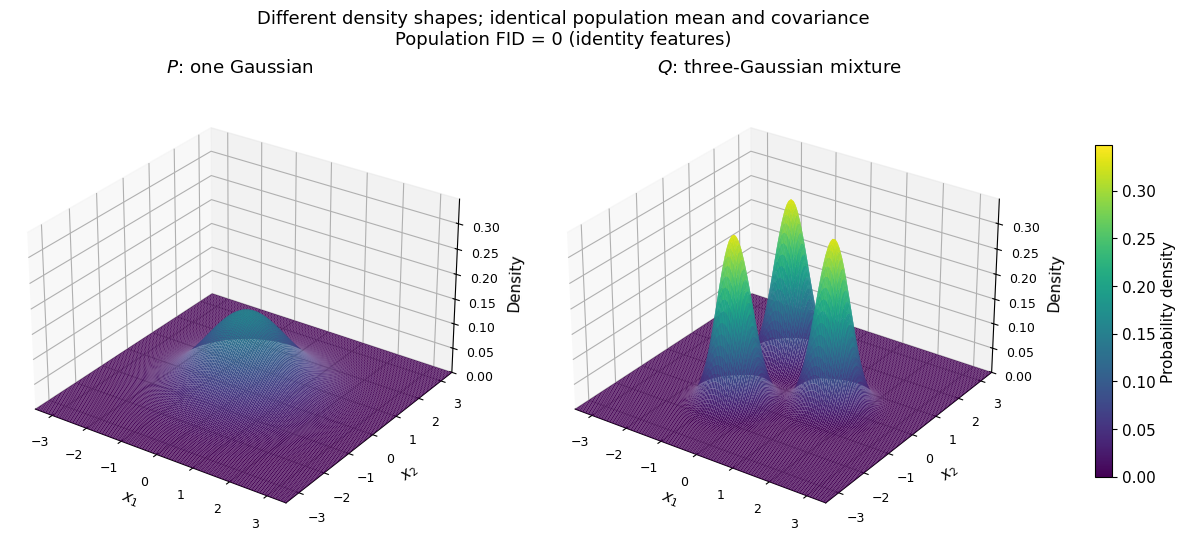

In [4]:
# This section uses only the population parameters and log-density functions above.
DENSITY_VIEW = {
    "limit": 3.5,
    "grid_size": 161,
    "elevation": 28,
    "azimuth": -55,
}
grid_axis = np.linspace(-DENSITY_VIEW["limit"], DENSITY_VIEW["limit"],
                        DENSITY_VIEW["grid_size"])
grid_x1, grid_x2 = np.meshgrid(grid_axis, grid_axis)
grid_points = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
p_density = np.exp(log_p(grid_points)).reshape(grid_x1.shape)
q_density = np.exp(log_q(grid_points)).reshape(grid_x1.shape)
assert np.isfinite(p_density).all() and np.isfinite(q_density).all()
assert p_density.min() >= 0 and q_density.min() >= 0

# One common density scale: separate normalization would conceal the peak-height difference.
density_max = 1.05 * max(float(p_density.max()), float(q_density.max()))
density_norm = Normalize(vmin=0, vmax=density_max)
density_cmap = plt.get_cmap("viridis")
density_levels = np.linspace(0, density_max, 15)
density_titles = [r"$P$: one Gaussian", r"$Q$: three-Gaussian mixture"]
density_3d_figure, density_axes = plt.subplots(
    1, 2, figsize=(12.5, 5.4), subplot_kw={"projection": "3d"},
    constrained_layout=True)
for ax, density, title in zip(density_axes, [p_density, q_density], density_titles):
    surface = ax.plot_surface(
        grid_x1, grid_x2, density, cmap=density_cmap, norm=density_norm,
        rcount=DENSITY_VIEW["grid_size"], ccount=DENSITY_VIEW["grid_size"],
        linewidth=0, antialiased=True, rasterized=True)
    ax.set(xlim=(-DENSITY_VIEW["limit"], DENSITY_VIEW["limit"]),
           ylim=(-DENSITY_VIEW["limit"], DENSITY_VIEW["limit"]),
           zlim=(0, density_max), xlabel=r"$x_1$", ylabel=r"$x_2$",
           zlabel="Density", title=title)
    ax.view_init(elev=DENSITY_VIEW["elevation"], azim=DENSITY_VIEW["azimuth"])
    ax.set_box_aspect((1, 1, 0.65))
    ax.tick_params(labelsize=9)
density_3d_figure.colorbar(surface, ax=density_axes, shrink=0.72,
                           pad=0.08, label="Probability density")
density_3d_figure.suptitle(
    "Different density shapes; identical population mean and covariance\n"
    "Population FID = 0 (identity features)", fontsize=13)
plt.show()


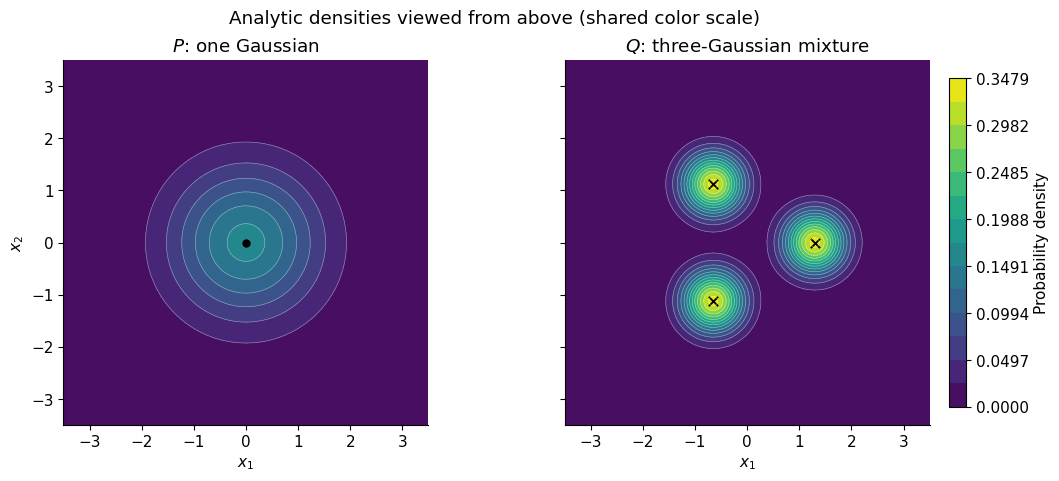

In [5]:
density_contour_figure, contour_axes = plt.subplots(
    1, 2, figsize=(11.2, 4.7), sharex=True, sharey=True, constrained_layout=True)
for ax, density, title in zip(contour_axes, [p_density, q_density], density_titles):
    contours = ax.contourf(grid_x1, grid_x2, density, levels=density_levels,
                           cmap=density_cmap, norm=density_norm)
    ax.contour(grid_x1, grid_x2, density, levels=density_levels[1:-1],
               colors="white", linewidths=0.45, alpha=0.45)
    ax.set(xlabel=r"$x_1$", title=title)
    ax.set_aspect("equal", adjustable="box")
contour_axes[0].scatter(0, 0, c="black", s=25, zorder=3)
contour_axes[1].scatter(*means.T, c="black", marker="x", s=45, linewidths=1.3)
contour_axes[0].set_ylabel(r"$x_2$")
density_contour_figure.colorbar(contours, ax=contour_axes, shrink=0.9,
                                pad=0.02, label="Probability density")
density_contour_figure.suptitle("Analytic densities viewed from above (shared color scale)")
plt.show()


## One neural RDR fit

Use the main simulation's B8-Res64 architecture, output slope 2, and Hellinger
objective. In two dimensions its learned input projection has two coordinates.
The shared CPU trainer uses full-batch AdamW and restores the checkpoint with
minimum validation Hellinger loss. Analytic RDR values are used only for evaluation.
This illustrative fit is not an additional repeated benchmark or model-selection study.

In [6]:
initialization_seed = int(np.random.SeedSequence([CONFIG["seed"], 99]).generate_state(1)[0])
model = make_ratio_mlp(2, architecture=CONFIG["architecture"],
                       output_alpha=CONFIG["output_alpha"], seed=initialization_seed)
start = time.perf_counter()
model, training_metadata, history = fit_ratio_mlp(
    model, *samples["train"], *samples["validation"], loss=CONFIG["loss"],
    min_epochs=CONFIG["min_epochs"], max_epochs=CONFIG["max_epochs"],
    patience=CONFIG["patience"])
fit_seconds = time.perf_counter() - start


def predict_rdr(x):
    model.eval()
    with torch.no_grad():
        predictions = model(torch.as_tensor(x, dtype=torch.float32)).numpy().ravel()
    assert np.isfinite(predictions).all()
    assert np.all((predictions >= 0) & (predictions <= 2))
    return predictions


r_p, r_q = predict_rdr(x_p_eval), predict_rdr(x_q_eval)
metrics = {
    "evaluation_rdr_mse": float(0.5 * (np.mean((r_p - truth_p)**2)
                                       + np.mean((r_q - truth_q)**2))),
    "evaluation_balanced_brier": float(0.5 * (np.mean((r_p / 2 - 1)**2)
                                             + np.mean((r_q / 2)**2))),
    "evaluation_sample_fid": empirical_fid,
    "population_fid_exact": 0.0,
    "population_fid_numerical_check": population_fid_numeric,
}
print(f"One CPU fit: {len(history)} epochs, best epoch {training_metadata['best_epoch']}, "
      f"{fit_seconds:.1f} seconds")
print(json.dumps(metrics, indent=2))

One CPU fit: 330 epochs, best epoch 173, 12.8 seconds
{
  "evaluation_rdr_mse": 0.009231928495259402,
  "evaluation_balanced_brier": 0.1671348661184311,
  "evaluation_sample_fid": 0.0017119518003964073,
  "population_fid_exact": 0.0,
  "population_fid_numerical_check": 2.220446049250313e-16
}


## Compact scatterplot for the paper

The figure is a single row, 7.2 × 1.85 inches, with short panel labels and one
shared colorbar. Edit `SCATTER_STYLE` and rerun the plotting cell to change its
size or point size without refitting. The density plots above remain separate.

All panels use the same independent evaluation points and drawing order.
A wider horizontal window with equal unit scaling preserves the geometry;
crosses mark the component means.
RDR colors run from blue ($q>p$) through white ($p=q$) to red ($p>q$).
The evaluation MSE is printed above and saved in the JSON summary.

**Suggested caption:** Moment-matched Gaussian $P$ and three-component Gaussian
mixture $Q$, both with mean zero and covariance $I_2$, have population FID zero
in the identity coordinates. Panels show samples, exact RDR $2p/(p+q)$, and
estimated RDR; blue indicates excess density under $Q$, and red a deficit.


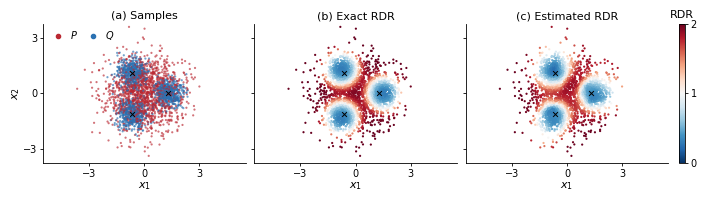

In [7]:
plot_rng = np.random.default_rng(np.random.SeedSequence([CONFIG["seed"], 100]))
n_plot = min(CONFIG["n_scatter_per_distribution"], CONFIG["n_evaluation"])
if n_plot < 1:
    raise ValueError("Use at least one scatter point per distribution.")
idx_p = plot_rng.choice(len(x_p_eval), n_plot, replace=False)
idx_q = plot_rng.choice(len(x_q_eval), n_plot, replace=False)
order = plot_rng.permutation(2 * n_plot)  # avoid painting one source over the other
x_plot = np.vstack([x_p_eval[idx_p], x_q_eval[idx_q]])[order]
source = np.r_[np.ones(n_plot), np.zeros(n_plot)][order]
truth_plot = np.r_[truth_p[idx_p], truth_q[idx_q]][order]
fitted_plot = np.r_[r_p[idx_p], r_q[idx_q]][order]

# Compact paper row; edit this dictionary and rerun just this cell to restyle.
SCATTER_STYLE = {"figsize": [7.2, 1.85], "font_size": 8, "point_size": 2.5,
                 "horizontal_padding": 1.45}
cmap, norm = plt.get_cmap("RdBu_r"), Normalize(vmin=0, vmax=2)
p_color, q_color = cmap(norm(1.75)), cmap(norm(0.25))
source_colors = np.array([q_color, p_color])[source.astype(int)]
limit = max(3.3, float(np.max(np.abs(x_plot))) + 0.15)

with plt.rc_context({"font.size": SCATTER_STYLE["font_size"],
                     "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7}):
    figure, axes = plt.subplots(1, 3, figsize=SCATTER_STYLE["figsize"],
                                sharex=True, sharey=True, layout="compressed")
    figure.get_layout_engine().set(w_pad=0.025, h_pad=0.015, wspace=0.025)
    axes[0].scatter(*x_plot.T, c=source_colors, s=SCATTER_STYLE["point_size"],
                    alpha=0.65, linewidths=0, rasterized=True)
    axes[0].set_title("(a) Samples", pad=3)
    axes[0].legend(handles=[
        Line2D([], [], marker="o", ls="", color=p_color, markersize=3, label=r"$P$"),
        Line2D([], [], marker="o", ls="", color=q_color, markersize=3, label=r"$Q$"),
    ], loc="upper left", ncol=2, frameon=False, handletextpad=0.2,
        columnspacing=0.6, borderaxespad=0.15)
    for ax, values, title in zip(axes[1:], [truth_plot, fitted_plot],
                                  ["(b) Exact RDR", "(c) Estimated RDR"]):
        scatter = ax.scatter(*x_plot.T, c=values, cmap=cmap, norm=norm,
                             s=SCATTER_STYLE["point_size"], alpha=1,
                             linewidths=0, rasterized=True)
        ax.set_title(title, pad=3)
    for ax in axes:
        ax.scatter(*means.T, marker="x", c="black", s=12, linewidths=0.7)
        # Wider coordinate window keeps equal unit scaling in a low, wide panel.
        x_limit = SCATTER_STYLE["horizontal_padding"] * limit
        ax.set(xlim=(-x_limit, x_limit), ylim=(-limit, limit),
               xticks=[-3, 0, 3], yticks=[-3, 0, 3])
        ax.set_xlabel(r"$x_1$", labelpad=1)
        ax.set_aspect("equal", adjustable="box")
        ax.tick_params(length=2, width=0.6, pad=2)
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
    axes[0].set_ylabel(r"$x_2$", labelpad=1)
    colorbar = figure.colorbar(scatter, ax=axes[1:], fraction=0.025,
                               pad=0.025, aspect=22, ticks=[0, 1, 2])
    colorbar.ax.set_title("RDR", fontsize=8, pad=4)
    colorbar.ax.tick_params(labelsize=7, length=2, width=0.6, pad=2)
    colorbar.outline.set_linewidth(0.6)
    plt.show()


## Optional export

With `OUTPUT_DIR=None`, the results stay inline. Set it in the configuration
cell to save each figure as PDF and PNG:

- `moment_matched_fid_density_3d`: the two analytic density surfaces.
- `moment_matched_fid_density_contours`: the paired contour maps.
- `moment_matched_fid_rdr`: the compact paper scatterplot (7.2 × 1.85 inches).

`moment_matched_fid_summary.json` records population parameters, exact and
sample FID, seeds, split sizes, fit and plotting settings, package versions and
independent evaluation metrics. The PDFs retain vector labels and rasterize
the 3D surfaces and scatter points. Rerunning all cells regenerates one fit
and all three figures.


In [8]:
summary = {
    "configuration": CONFIG,
    "density_view": DENSITY_VIEW,
    "scatter_style": SCATTER_STYLE,
    "feature_map": "identity on R^2",
    "population": {"p_mean": mean_p.tolist(), "p_covariance": cov_p.tolist(),
                   "q_weights": weights.tolist(), "q_component_means": means.tolist(),
                   "q_component_covariance": component_cov.tolist(),
                   "q_mean": mean_q.tolist(), "q_covariance": cov_q.tolist()},
    "rng": {"data_stream_key": "[seed, split_id, source_id]",
            "split_ids": SPLIT_IDS, "source_ids": {"P": 0, "Q": 1},
            "initialization_stream_key": [CONFIG["seed"], 99],
            "initialization_seed": initialization_seed,
            "plot_stream_key": [CONFIG["seed"], 100]},
    "training": training_metadata,
    "fit_seconds": fit_seconds,
    "metrics": metrics,
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "scipy": scipy.__version__, "torch": torch.__version__,
                 "matplotlib": matplotlib.__version__},
}
if OUTPUT_DIR is not None:
    output_dir = Path(OUTPUT_DIR).expanduser().resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    figures = {"moment_matched_fid_density_3d": density_3d_figure,
               "moment_matched_fid_density_contours": density_contour_figure,
               "moment_matched_fid_rdr": figure}
    for name, plot in figures.items():
        plot.savefig(output_dir / f"{name}.pdf")
        plot.savefig(output_dir / f"{name}.png", dpi=220)
    (output_dir / "moment_matched_fid_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n")
    print(f"Saved all three figures and summary to {output_dir}")
else:
    print("Inline results ready. Set OUTPUT_DIR to export all three figures and summary.")

Inline results ready. Set OUTPUT_DIR to export all three figures and summary.
